#### House Prediction 

In [176]:
# import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [177]:
df = pd.read_csv('housing.csv')

In [178]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [179]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


#### Data Cleaning 

In [180]:
# missing value
df.isnull().sum()


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [181]:
# fill missing value
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [182]:
# check duplicated
df.duplicated().sum()
# 0 dubliated

np.int64(0)

In [183]:
df.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='object')

#### Feature Engineering
##### Important feature that needs to make 
1. median_income
2. housing_median_age
3. rooms_per_household
4. total_beadrooms
5. population_per_household
6. latitude
7. longitude
8. ocean_proximity
9. location_score

In [184]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [185]:
df['rooms_per_households']= (df['total_rooms']/df['households']).round().astype(int)


In [186]:
df['population_per_household'] = (df['population']/df['households']).round().astype(int)

In [187]:
# drop useless feature
df.drop(["total_rooms","population","households"], axis=1,inplace=True)

In [188]:
# encode 
df['ocean_proximity'].unique()

from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
df['ocean_proximity'] = encoder.fit_transform(df['ocean_proximity'])

In [189]:
mapping = dict(zip(encoder.classes_, range(len(encoder.classes_))))
print(mapping)

{'<1H OCEAN': 0, 'INLAND': 1, 'ISLAND': 2, 'NEAR BAY': 3, 'NEAR OCEAN': 4}


In [190]:
# remove outlier
numeric_cols = df.select_dtypes(include=['int64','float64']).columns.drop("median_house_value")
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

In [191]:
# save cleaned
df.to_csv('clean_housing.csv',index=False)

#### EDA

In [192]:
df = pd.read_csv('clean_housing.csv')

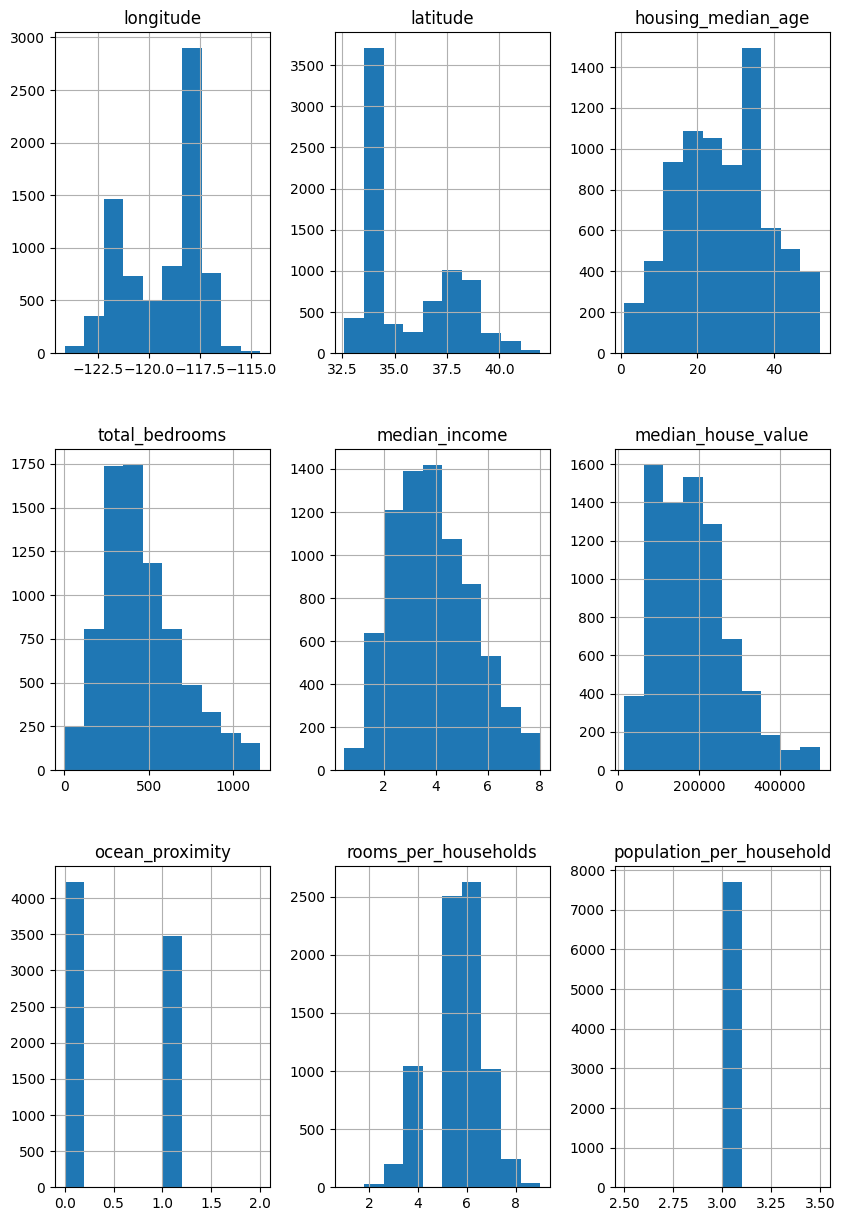

In [193]:
# histogram
df.hist(bins=10,figsize=(10,15))
plt.show()

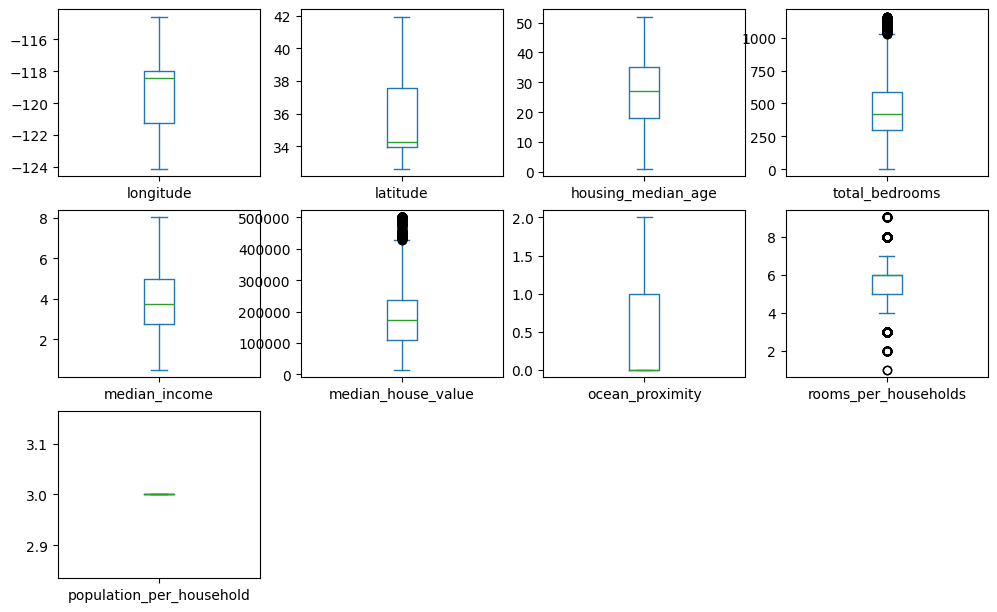

In [194]:
# box plot
df.plot(kind='box', subplots=True, layout=(4,4), figsize=(12,10))
plt.show()

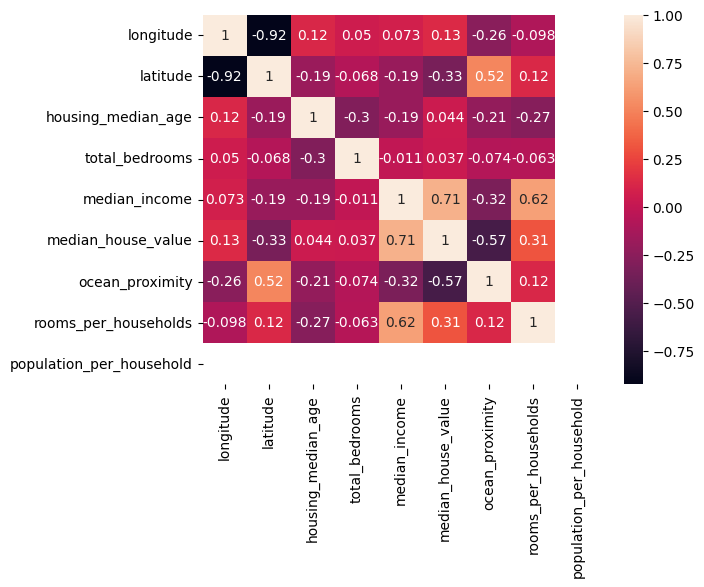

In [195]:
# correlation
sns.heatmap(df.corr(),annot=True)
plt.show()

##### ML training

In [196]:
# define independence and dependence variable
x = df.drop(columns='median_house_value')
y = df['median_house_value']

In [197]:
# split dataset
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,random_state=42)

In [198]:
# feature scaling
from sklearn.preprocessing import StandardScaler
scaller = StandardScaler()
x_train = scaller.fit_transform(x_train)
x_test = scaller.transform(x_test)

In [199]:
# apply linear regression
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [200]:
y

0       431000.0
1       217000.0
2       247600.0
3       283500.0
4       282500.0
          ...   
7701     98300.0
7702    116800.0
7703     78100.0
7704     77100.0
7705     89400.0
Name: median_house_value, Length: 7706, dtype: float64

In [201]:
# prediction
y_pred = model.predict(x_test)
y_pred

array([185047.37071638, 193672.52682283, 294516.03394984, ...,
       174155.45916537, 336071.88603666, 298437.20505782], shape=(1927,))

<Axes: xlabel='median_house_value'>

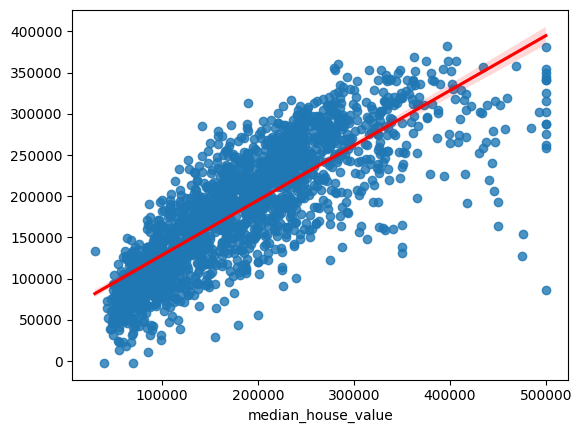

In [202]:
# visualize
sns.regplot(x=y_test,y=y_pred,line_kws={'color':'red'})

In [203]:
# Slope and intercept
print(f'Slpoe or coeffcient : {model.coef_}')
print(f'Intercept : {model.intercept_}')

Slpoe or coeffcient : [-35291.91515696 -39767.58358761   8278.65186144   3615.97771268
  55077.3307366  -22792.87610098   2653.00252905      0.        ]
Intercept : 185514.6321162833


In [204]:
### Performance Matrix
from sklearn.metrics import mean_absolute_error,mean_squared_error
mse = mean_absolute_error(y_test,y_pred)
mse


39341.454261555176

In [205]:
# (Accuracy of Model)
from sklearn.metrics import r2_score
score = r2_score(y_test,y_pred)
print(f'model accuracy {score*100}%')

model accuracy 65.0081239401795%


In [209]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7706 entries, 0 to 7705
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 7706 non-null   float64
 1   latitude                  7706 non-null   float64
 2   housing_median_age        7706 non-null   float64
 3   total_bedrooms            7706 non-null   float64
 4   median_income             7706 non-null   float64
 5   ocean_proximity           7706 non-null   int64  
 6   rooms_per_households      7706 non-null   int64  
 7   population_per_household  7706 non-null   int64  
dtypes: float64(5), int64(3)
memory usage: 481.8 KB


In [ ]:
model.predict(scaller.transform([[-122,37,45,200,9,1,7,5]]))


c:\Users\shali\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([382206.92967802])

#### save in pkl

In [215]:
import pickle
from sklearn.metrics import r2_score

pred = model.predict(x_test)

accuracy = r2_score(y_test, pred)

pickle.dump((model, scaller, accuracy), open("model.pkl","wb"))